# Create county forecast table for Population Hub

Using the county controls deliverable spreadsheet as an input, this script creates a long-form verison of the table that is formatted as needed to feed the chart and map in the interactive dashboard on the [county forecasts](https://experience.arcgis.com/experience/cd446109151f474db74b13fa0795023c/page/County-Projections/) page in the Population Hub.

## Prerequisites

  1. Ensure that a working copy of the [morpc-common](https://github.com/morpc/morpc-common) repository is available in the parent directory of this script (i.e. at ../morpc-common)
  1. Ensure that a working copy of the [morpc-lookup](https://github.com/morpc/morpc-lookup) repository is available in the parent directory of this script (i.e. at ../morpc-lookup)
  1. Ensure that the primary county controls spreadsheet is up to date and is available at the location specified in COUNTYCONTROLS_TABLE_FILEPATH.  It must include a sheet with the name specified in COUNTYCONTROLS_TABLE_SHEETNAME which includes all of the variables in semi-long format (each record corresponds to a specific county and variable and has several fields containing the variable values for each of the forecast years). 

## Setup

### Libraries

In [1]:
import os
import pandas as pd
import geopandas as gpd
import json
import shutil
import math
import datetime
import sys
sys.path.append(os.path.normpath("../morpc-common"))
import morpc

### Parameters

In [2]:
# The keys of INCLUDE_VARS are variables from the county controls to include in the interactive dashboard.  The values
# are the order that the variables should be listed.  The first variable (i.e. the one with the lowest order) is especially
# important as this can be selected by default in the dashboard.
INCLUDE_VARS = {
    'Population': "0",
    'Population Ages under 18': "1",
    'Population Ages 18 - 64': "2", 
    'Population Ages 65 and older': "3",
    'Households': "4", 
    'Housing Units': "5", 
    'Total Employment': "6", 
    'Workers': "7"
}

## Uncomment one of the following rounding types to round all values in the data
# No rounding will be performed
#ROUNDING_TYPE = None                       
# Values will be rounded to the digit specified in ROUND_DECPLACES (see documentation for round())
#ROUNDING_TYPE = "decimal_places"           
# Values will be rounded to the number of significant digits specified in ROUND_SIGFIGS or to the hundreds 
# place, whichever is less precise.
#ROUNDING_TYPE = "significant_figures"
# Hybrid place-based rounding scheme. Values are rounded to the hundreds place except values less than 1000 
# which are rounded to tens place.  ROUND_DECPLACES and ROUND_SIGFIGS are not used (parameters are hardcoded below)
ROUNDING_TYPE = "hybrid"

ROUND_DECPLACES = -3
ROUND_SIGFIGS = 3

### Input data

In [3]:
# Primary deliverable for county controls, namely a spreadsheet with a tab containing all of the variables in semi-long form.
COUNTYCONTROLS_TABLE_FILEPATH = os.path.normpath("./deliverables/CountyControls_WEB.xlsx")
COUNTYCONTROLS_TABLE_SHEETNAME = "All Data (Unformatted)" 

# List of counties contained in MORPC region with some attributes
MORPC_COUNTIES_TABLE_SOURCE_FILEPATH = os.path.normpath("../morpc-lookup/MORPC_Counties.csv")
MORPC_COUNTIES_SCHEMA_SOURCE_FILEPATH = os.path.normpath("../morpc-lookup/MORPC_Counties_schema.json")

# County geographies
COUNTY_GEO_YEAR = 2020
COUNTY_GEO_URL = "https://www2.census.gov/geo/tiger/GENZ{0}/shp/cb_{0}_us_county_500k.zip".format(COUNTY_GEO_YEAR)

if (datetime.datetime.now().year != COUNTY_GEO_YEAR):
    print("WARNING: Release version of county geographies does not match current year.  Consider whether newer geographies should be used.")

### Output data

In [4]:
OUTPUT_DATA_DIR = os.path.normpath("./output_data")
if not os.path.exists(OUTPUT_DATA_DIR):
    os.makedirs(OUTPUT_DATA_DIR)
    
COUNTYCONTROLS_GEO_FILENAME = "countyControlsHubData.shp"
COUNTYCONTROLS_GEO_FILEPATH = os.path.normpath(os.path.join(OUTPUT_DATA_DIR, "shapefile", COUNTYCONTROLS_GEO_FILENAME))
COUNTYCONTROLS_GEO_ZIP_FILEPATH = os.path.normpath(os.path.join(OUTPUT_DATA_DIR, COUNTYCONTROLS_GEO_FILENAME.replace(".shp",".zip")))
COUNTYCONTROLS_GEO_SCHEMA_FILEPATH = COUNTYCONTROLS_GEO_FILEPATH.replace(".shp", "_schema.json")

## Load input data

### MORPC counties

The MORPC counties lookup table is used to extract only the required features from the Census county geography shapefile.  

First load the schema for the counties data.

In [5]:
with open(MORPC_COUNTIES_SCHEMA_SOURCE_FILEPATH) as f:
    morpcCountiesSchema = json.load(f)

Load the data and re-cast the fields to the appropriate types based on the schema.

In [6]:
morpcCounties = pd.read_csv(MORPC_COUNTIES_TABLE_SOURCE_FILEPATH)
morpcCounties = morpc.cast_field_types(morpcCounties, morpcCountiesSchema)
morpcCounties.head()

Casting field STATE_ID as type string.
Casting field COUNTY_ID as type string.
Casting field COUNTY_NAME as type string.
Casting field GEOID as type string.
Casting field LongGEOID as type string.
Casting field REGION_7 as type boolean.
Casting field CEDS_REGION as type boolean.
Casting field CORPO_REGION as type boolean.


,STATE_ID,COUNTY_ID,COUNTY_NAME,GEOID,LongGEOID,REGION_7,CEDS_REGION,CORPO_REGION
0,39,41,Delaware,39041,05000US39041,True,True,True
1,39,45,Fairfield,39045,05000US39045,True,True,True
2,39,47,Fayette,39047,05000US39047,False,False,False
3,39,49,Franklin,39049,05000US39049,True,True,True
4,39,73,Hocking,39073,05000US39073,False,False,False


### County controls

This section will load the data from the primary county controls spreadsheet, extract the required variables, and reformat the table in long format such that each record corresponds to a particular year/county/variable combination.

First load the data.

In [7]:
countyControlsRaw = pd.read_excel(COUNTYCONTROLS_TABLE_FILEPATH, sheet_name=COUNTYCONTROLS_TABLE_SHEETNAME)

## Transform the data

Extract only the required variables and geographies and reformat the data as required by the dashboard.  The regional summaries will not be included in the dataset, but the 15-county region summary will be computed by the dashboard.

In [8]:
countyControls = countyControlsRaw \
    .loc[
        (countyControlsRaw["VARIABLE"].isin(INCLUDE_VARS.keys())) &   # Extract only the required variables
        (countyControlsRaw["COUNTY"] != "10-County Region") &         # Omit 10-county regional summary
        (countyControlsRaw["COUNTY"] != "15-County Region")           # Omit 15-county regional summary
    ] \
    .drop(columns="CATEGORY") \
    .melt(id_vars=["COUNTY","VARIABLE"], var_name="YEAR", value_name='VALUE')  # Convert the data to long format

# Convert all values to integers.
countyControls["VALUE"] = countyControls["VALUE"].round(0).astype("Int64")

We want the dashboard output to convey some uncertainty. Optionally, reduce the precision of the data values by rounding the values using the specified rounding scheme.

In [9]:
countyControlsRounded = countyControls.copy()

if ROUNDING_TYPE == None:
    pass
elif ROUNDING_TYPE == "significant_digits":
    # If using significant figures, figure out how many digits are in the value.  Subtract the number of digits from the number
    # of significant figures to determine the rounding digit.  If the rounding digit is smaller than the 100s place, round to the
    # 100s place instead.
    countyControlsRounded["VALUE"] = countyControlsRounded["VALUE"].apply(lambda x: round(x, min(ROUND_SIGFIGS-int(math.ceil(math.log10(abs(x)))), -2)))
elif ROUNDING_TYPE == "decimal_places":
    # If using decimal places, simply round to the specified digit.
    countyControlsRounded["VALUE"] = countyControlsRounded["VALUE"].apply(lambda x: round(x, ROUND_DECPLACES))
elif ROUNDING_TYPE == "hybrid":
    # Round to the hundreds place unless the value is less than 1000 in which case round to tens place
    countyControlsRounded["VALUE"] = countyControlsRounded["VALUE"].apply(lambda x: round(x, -2) if x>=1000 else round(x, -1))
else:
    print("ERROR: No handler for rounding type {}.".format(ROUNDING_TYPE))
    raise RuntimeError

# Regardless of the rounding method, make sure all values end up as integers.
countyControlsRounded["VALUE"] = countyControlsRounded["VALUE"].round(0).astype("Int64")

countyControlsRounded

,COUNTY,VARIABLE,YEAR,VALUE
0,Delaware,Households,2020,74800
1,Fairfield,Households,2020,58300
2,Fayette,Households,2020,11900
3,Franklin,Households,2020,526200
4,Hocking,Households,2020,11400
...,...,...,...,...
835,Morrow,Workers,2050,20400
836,Perry,Workers,2050,15800
837,Pickaway,Workers,2050,33600
838,Ross,Workers,2050,29200


## Check the data

Check the impacts of rounding.

In [10]:
roundingError = countyControls.copy().set_index(["COUNTY","VARIABLE","YEAR"]).rename(columns={"VALUE":"ORIGINAL"})
roundingError = roundingError.join(countyControlsRounded.set_index(["COUNTY","VARIABLE","YEAR"]).rename(columns={"VALUE":"ROUNDED"}))
roundingError["ABSERROR"] = roundingError["ROUNDED"] - roundingError["ORIGINAL"]
roundingError["PCTERROR"] = roundingError["ABSERROR"]/roundingError["ORIGINAL"]*100
roundingError = roundingError.reset_index()
roundingError = roundingError.drop(columns=["ORIGINAL","ROUNDED"])
roundingError.head()

,COUNTY,VARIABLE,YEAR,ABSERROR,PCTERROR
0,Delaware,Households,2020,43,0.05752
1,Fairfield,Households,2020,-3,-0.005146
2,Fayette,Households,2020,25,0.210526
3,Franklin,Households,2020,-42,-0.007981
4,Hocking,Households,2020,-23,-0.201348


In [11]:
roundingError.drop(columns=["YEAR","COUNTY"]).groupby("VARIABLE").mean()

,ABSERROR,PCTERROR
VARIABLE,,
Households,-0.342857,-0.011709
Housing Units,-4.247619,0.000339
Population,-0.419048,0.000552
Population Ages 18 - 64,3.438095,0.005777
Population Ages 65 and older,0.571429,-0.002694
Population Ages under 18,-4.514286,-0.009727
Total Employment,0.114286,-0.01573
Workers,1.742857,-0.00397


In [12]:
roundingError.drop(columns=["YEAR","COUNTY"]).groupby("VARIABLE").max()

,ABSERROR,PCTERROR
VARIABLE,,
Households,50,0.311091
Housing Units,49,0.309681
Population,49,0.174378
Population Ages 18 - 64,48,0.211715
Population Ages 65 and older,50,0.787402
Population Ages under 18,45,0.653364
Total Employment,49,0.589664
Workers,50,0.302928


VARIABLE
Households                      [[AxesSubplot(0.125,0.125;0.336957x0.755), Axe...
Housing Units                   [[AxesSubplot(0.125,0.125;0.336957x0.755), Axe...
Population                      [[AxesSubplot(0.125,0.125;0.336957x0.755), Axe...
Population Ages 18 - 64         [[AxesSubplot(0.125,0.125;0.336957x0.755), Axe...
Population Ages 65 and older    [[AxesSubplot(0.125,0.125;0.336957x0.755), Axe...
Population Ages under 18        [[AxesSubplot(0.125,0.125;0.336957x0.755), Axe...
Total Employment                [[AxesSubplot(0.125,0.125;0.336957x0.755), Axe...
Workers                         [[AxesSubplot(0.125,0.125;0.336957x0.755), Axe...
dtype: object

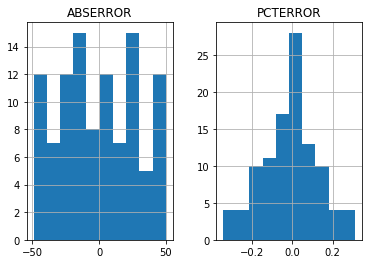

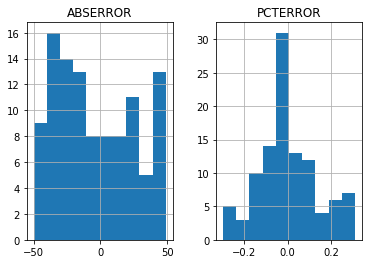

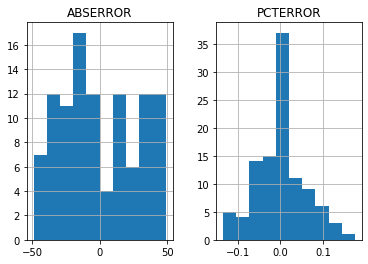

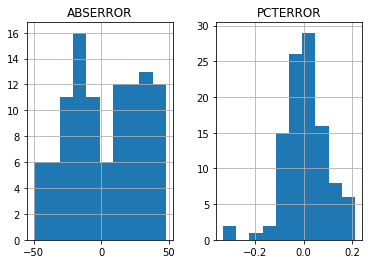

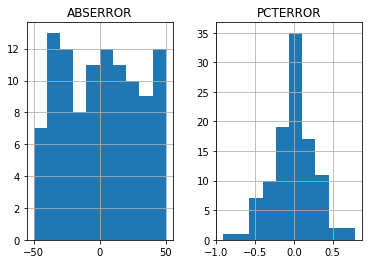

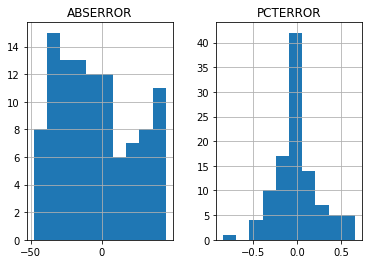

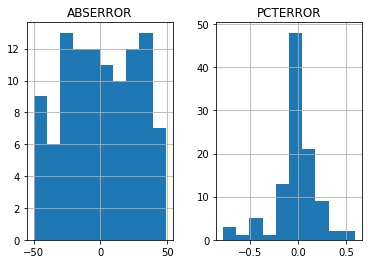

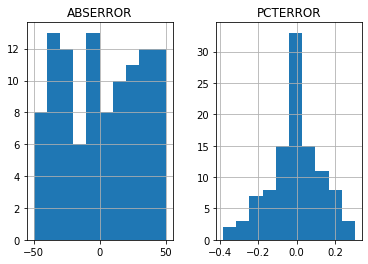

In [14]:
roundingError.drop(columns=["YEAR","COUNTY"]).groupby("VARIABLE").hist()

In [29]:
roundingErrorSum = countyControls.copy().set_index(["COUNTY","VARIABLE","YEAR"]).rename(columns={"VALUE":"ORIGINAL"})
roundingErrorSum = roundingErrorSum.join(countyControlsRounded.set_index(["COUNTY","VARIABLE","YEAR"]).rename(columns={"VALUE":"ROUNDED"}))
roundingErrorSum = roundingErrorSum.reset_index()
roundingErrorSum = roundingErrorSum.drop(columns=["YEAR","COUNTY"]).groupby("VARIABLE").sum()
roundingErrorSum["ABSERROR"] = roundingErrorSum["ROUNDED"] - roundingErrorSum["ORIGINAL"]
roundingErrorSum["PCTERROR"] = roundingErrorSum["ABSERROR"]/roundingErrorSum["ORIGINAL"]*100
roundingErrorSum

,ORIGINAL,ROUNDED,ABSERROR,PCTERROR
VARIABLE,,,,
Households,7496636,7496600,-36,-0.00048
Housing Units,8129046,8128600,-446,-0.005486
Population,19618144,19618100,-44,-0.000224
Population Ages 18 - 64,11915139,11915500,361,0.00303
Population Ages 65 and older,3262640,3262700,60,0.001839
Population Ages under 18,4440374,4439900,-474,-0.010675
Total Employment,9361588,9361600,12,0.000128
Workers,9622117,9622300,183,0.001902


## Create spatial data

The dashboard requires a spatial feature class.  Create it now by joining Census geographies to the county controls table.

First read the data directly from the Census website.

In [15]:
countiesRaw = gpd.read_file(COUNTY_GEO_URL)

Drop some unneeded fields, convert GEOID and NAME fields to strings, and extract only the features in the MORPC region.

In [16]:
counties = countiesRaw.copy() \
    .filter(items=["GEOID", "NAME", "geometry"], axis="columns") \
    .astype({
        "GEOID":"string",
        "NAME":"string"
    }) \
    .set_index("GEOID") \
    .filter(items=morpcCounties["GEOID"], axis="index") \
    .reset_index()
counties.head()

,GEOID,NAME,geometry
0,39041,Delaware,"POLYGON ((-83.24959 40.36431, -83.24959 40.366..."
1,39045,Fairfield,"POLYGON ((-82.84290 39.56201, -82.84154 39.576..."
2,39047,Fayette,"POLYGON ((-83.66646 39.58846, -83.66534 39.598..."
3,39049,Franklin,"POLYGON ((-83.26088 40.00281, -83.25855 40.004..."
4,39073,Hocking,"POLYGON ((-82.74744 39.38190, -82.74520 39.412..."


Join the county geometries and identifiers to the county controls table, joining on county names. Then convert it to a GeoDataFrame.

In [17]:
temp = countyControlsRounded.merge(counties, left_on="COUNTY", right_on="NAME")
countyControlsGeo = gpd.GeoDataFrame(temp, geometry=temp["geometry"], crs=countiesRaw.crs)

Transform the data as required for the dashboard.

In [18]:
# Put the columns in a logical order and eliminate extraneous columns
countyControlsGeo = countyControlsGeo.filter(items=["GEOID","NAME","YEAR","VARIABLE","VALUE","geometry"], axis="columns")

# Reproject to Ohio State Plane South coordinate system
countyControlsGeo = countyControlsGeo.to_crs("EPSG:3735")

# Convert years to integers
countyControlsGeo["YEAR"] = countyControlsGeo["YEAR"].astype("Int64")

# Make sure that all values are integers.
countyControlsGeo["VALUE"] = countyControlsGeo["VALUE"].astype("Int64")

# Prepend the variable sort order to the variable name, then sort by ordered variable name.
countyControlsGeo["VARORDER"] = countyControlsGeo["VARIABLE"].map(INCLUDE_VARS)
countyControlsGeo["VARIABLE"] = countyControlsGeo["VARORDER"] + " " + countyControlsGeo["VARIABLE"]
countyControlsGeo = countyControlsGeo.drop(columns=["VARORDER"])
countyControlsGeo = countyControlsGeo.sort_values(by=["NAME","YEAR","VARIABLE"], ascending=True)

countyControlsGeo.head()

,GEOID,NAME,YEAR,VARIABLE,VALUE,geometry
2,39041,Delaware,2020,0 Population,215100,"POLYGON ((1759597.826 862040.093, 1759606.586 ..."
5,39041,Delaware,2020,1 Population Ages under 18,53900,"POLYGON ((1759597.826 862040.093, 1759606.586 ..."
3,39041,Delaware,2020,2 Population Ages 18 - 64,129500,"POLYGON ((1759597.826 862040.093, 1759606.586 ..."
4,39041,Delaware,2020,3 Population Ages 65 and older,31700,"POLYGON ((1759597.826 862040.093, 1759606.586 ..."
0,39041,Delaware,2020,4 Households,74800,"POLYGON ((1759597.826 862040.093, 1759606.586 ..."


Inspect a sample of the data.

In [19]:
countyControlsGeo.loc[(countyControlsGeo["YEAR"] == 2050) & (countyControlsGeo["VARIABLE"] == "0 Population")].explore(column="VALUE", scheme="FisherJenks", style_kwds={"color":"white"})

## Export data

Export the data as a Shapefile, then create a zip archive of the files at COUNTYCONTROLS_GEO_ZIP_FILEPATH, ready for upload to ArcGIS Online.

In [20]:
if not os.path.exists(os.path.dirname(COUNTYCONTROLS_GEO_FILEPATH)):
    os.makedirs(os.path.dirname(COUNTYCONTROLS_GEO_FILEPATH))
countyControlsGeo.to_file(COUNTYCONTROLS_GEO_FILEPATH, index=False)
shutil.make_archive(os.path.splitext(COUNTYCONTROLS_GEO_ZIP_FILEPATH)[0], "zip", os.path.dirname(COUNTYCONTROLS_GEO_FILEPATH), os.path.normpath("./"))

'C:\\Users\\aporr\\OneDrive - Mid-Ohio Regional Planning Commission\\morpc-county-controls\\output_data\\countyControlsHubData.zip'

## Upload data to ArcGIS Online

In theory, the only step required to update the dashboard is to "update" the underlying hosted feature layer as follows:

  1. Log into ArcGIS Online (MORPC organization)
  1. Navigate to the item page for the [countyControlsHubData hosted feature layer](https://morpc.maps.arcgis.com/home/item.html?id=513cc0566cd54e0f907350ac95e09aed)
  1. Click "Update Data", then "Overwrite Entire Layer".
  1. When prompted for the file to upload, select the zip file at COUNTYCONTROLS_GEO_ZIP_FILEPATH.  
  1. Open the [county forecasts](https://experience.arcgis.com/experience/cd446109151f474db74b13fa0795023c/page/County-Projections/) page in the Population Hub and verify that the chart and map reflect the new data.
  1. If necessary, troubleshoot or make changes to the [dashboard](https://morpc.maps.arcgis.com/apps/dashboards/d0d905833e714284b6b692b4e922a765) itself.